# **DELE CA1 Part A**


## **Part 1: Importing Libraries**
---

In [29]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from PIL import Image

from collections import Counter

from scipy.linalg import sqrtm
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

## **Part 2: Exploratory Data Analysis**
---

### 2.1 **Dataset Info** 

In [30]:
# df = pd.read_csv("C:/Users/Enzo/schEnzo/OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")
# df = pd.read_csv("C:/Users/tayen\OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")
df = pd.read_csv("C:/Users/kiloz/Documents/GitHub/DELE-CA2/emnist-letters-train.csv")

# Show the first few rows
print(df.head())

# Shape of dataset
print("Shape:", df.shape)  

# Info summary of dataset (columns, non-null counts, datatypes, memory)
print("\n", df.info())

   24    0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.552  0.553  0.554  \
0  -2  142  142  142  142  142  142  142  142  142  ...    142    142    142   
1  15    0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  14    0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  -2  120  120  120  120  120  120  120  120  120  ...    120    120    120   
4  -1  131  131  131  131  131  131  131  131  200  ...    131    131    131   

   0.555  0.556  0.557  0.558  0.559  0.560  0.561  
0    142    142    142    142    142    142    142  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3    120    120    120    120    120    120    120  
4    131    131    131    131    131    131    131  

[5 rows x 785 columns]
Shape: (64828, 785)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64828 entries, 0 to 64827
Columns: 785 entries, 24 to 0.561
dtypes: int64(785)
memory usage: 388.3 MB

 Non

### 2.2 **Class Distribution**

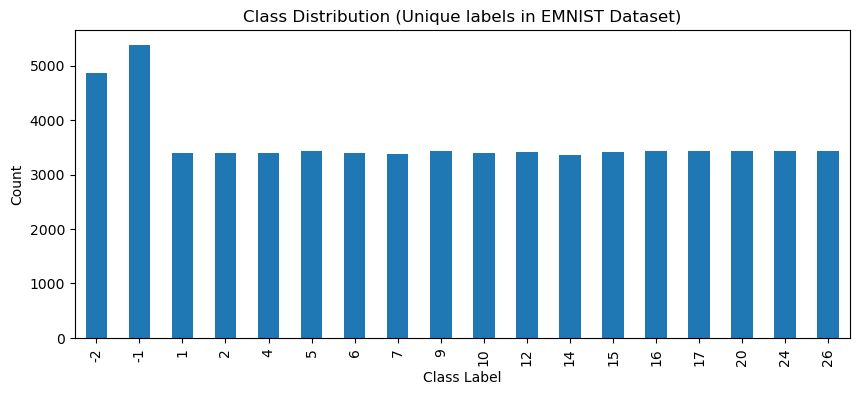

Unique labels in dataset: [-2, -1, 1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]


In [31]:
labels = df.iloc[:, 0]  # First column is label (1 to 26 for A-Z)

plt.figure(figsize=(10, 4))
labels.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution (Unique labels in EMNIST Dataset)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

print("Unique labels in dataset:", sorted(df.iloc[:, 0].unique()))

### 2.3 **Sample Images**

In [2]:
available_labels = sorted(df.iloc[:, 0].unique())

plt.figure(figsize=(len(available_labels) * 2, 4))  # Adjust figure width dynamically
for i, label in enumerate(available_labels):
    img = df[df.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    plt.subplot(2, len(available_labels) // 2 + 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

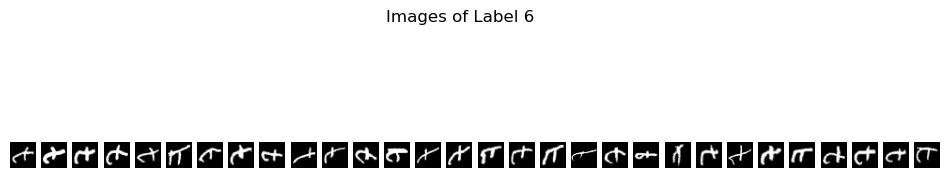

In [ ]:
label_to_show = 6
subset = df[df.iloc[:, 0] == label_to_show]

plt.figure(figsize=(12, 3))
for i in range(30):
    img = subset.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(1, 30, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(f"Images of Label {label_to_show}")
plt.show()

### 2.4 **Extraction and Filtering**

In [ ]:
labels = df.iloc[:, 0].values

# Filter out invalid labels, e.g. negative values
valid_labels_mask = labels >= 0
labels = labels[valid_labels_mask]

### 2.5 **Pixel Statistics**

#### 2.5.1 **Average Pixel Statistics**

In [ ]:
# Extract and reshape image pixels
X_filtered = df.iloc[valid_labels_mask, 1:].values.astype('float32')  # before reshape, for stats

# Compute mean and std before normalization
pixel_mean_raw = X_filtered.mean()
pixel_std_raw = X_filtered.std()
print("Raw pixel mean:", pixel_mean_raw)
print("Raw pixel std:", pixel_std_raw)

#### 2.5.2 **Per-Image Statistics**

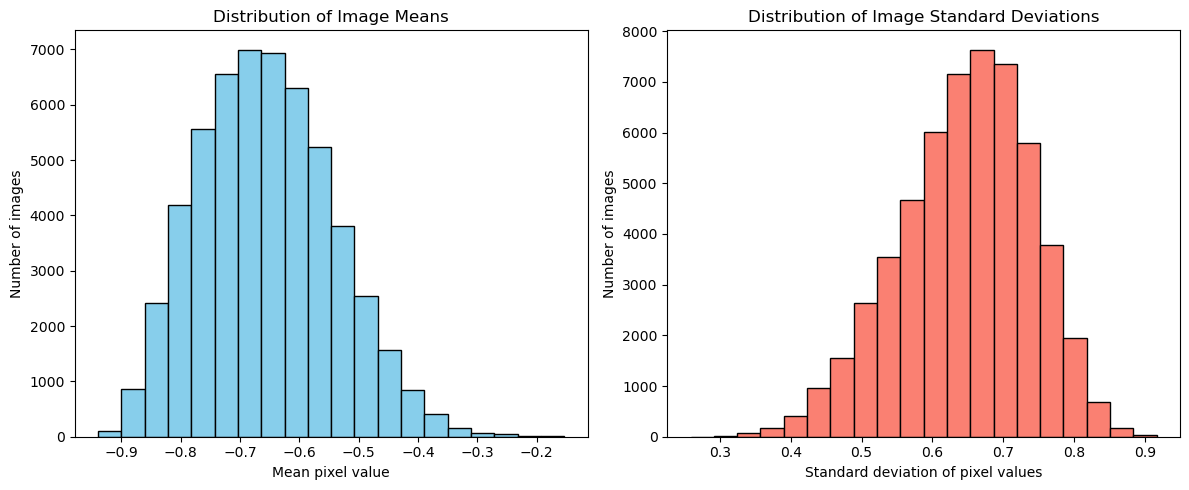

In [ ]:
image_means = X_filtered.reshape(X_filtered.shape[0], -1).mean(axis=1)
image_stds = X_filtered.reshape(X_filtered.shape[0], -1).std(axis=1)
plt.figure(figsize=(12, 5))

# Histogram of image means
plt.subplot(1, 2, 1)
plt.hist(image_means, bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Image Brightness (Mean Pixel Value)')
plt.xlabel('Mean pixel value')
plt.ylabel('Number of images')

# Histogram of image std deviations
plt.subplot(1, 2, 2)
plt.hist(image_stds, bins=20, color='salmon', edgecolor='black')
plt.title('Distribution of Image Contrast (Pixel Std Dev)')
plt.xlabel('Standard deviation of pixel values')
plt.ylabel('Number of images')

plt.tight_layout()
plt.show()

# **Part 3: Data Preprocessing**
---

### 3.1 **Mapping Class Labels**

In [ ]:
# Manual mapping from numeric label to letter
manual_label_map = {
    1: 'A',
    2: 'B',
    4: 'D',
    5: 'E',
    6: 'F',
    7: 'G',
    9: 'I',
    10: 'J',
    12: 'L',
    14: 'N',
    15: 'O',
    16: 'P',
    17: 'Q',
    20: 'T',
    24: 'X',
    26: 'Z'
}

# Map numeric labels to letter labels
letter_labels = np.array([manual_label_map[label] for label in labels])

# Define fixed letter order for indexing
letters = ['A', 'B', 'D', 'E', 'F', 'G', 'I', 'J', 'L', 'N', 'O', 'P', 'Q', 'T', 'X', 'Z']
letter_to_index = {letter: idx for idx, letter in enumerate(letters)}

# Map letter labels to numeric indices directly (no function)
y_filtered = np.array([letter_to_index[letter] for letter in letter_labels])

# Print the mapping dictionary only
print("Manual letter_to_index mapping:", letter_to_index)

Raw pixel mean: 43.943172
Raw pixel std: 84.49391
Manual letter_to_index mapping: {'A': 0, 'B': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'I': 6, 'J': 7, 'L': 8, 'N': 9, 'O': 10, 'P': 11, 'Q': 12, 'T': 13, 'X': 14, 'Z': 15}


### 3.2 **Normalising**

In [ ]:
# Normalize to [-1, 1] for GANs
X_filtered = (X_filtered - 127.5) / 127.5

X_filtered = X_filtered.reshape(-1, 28, 28, 1)

# Sanity check
print("Pixel mean:", X_filtered.mean())
print("Pixel std:", X_filtered.std())

Pixel mean: -0.65534747
Pixel std: 0.6626988


### 3.3 **Image Rotation**

In [37]:
def apply_rotation(images, labels):
    rotated_images = []
    
    # Labels that need 90° CW rotation and flip
    rotate_and_flip_labels = {1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26}

    for img, label in zip(images, labels):
        img = img.reshape(28, 28)
        
        if label in rotate_and_flip_labels:
            img = np.rot90(img, k=3)      # 90° clockwise
            img = np.fliplr(img)         # Flip left-right

        rotated_images.append(img)
    
    rotated_images = np.array(rotated_images).astype('float32')
    rotated_images = np.expand_dims(rotated_images, -1)  # Add channel dimension for grayscale
    return rotated_images

# Apply rotation + flip
X_filtered = apply_rotation(X_filtered, labels)

### 3.4 **Preview Images**

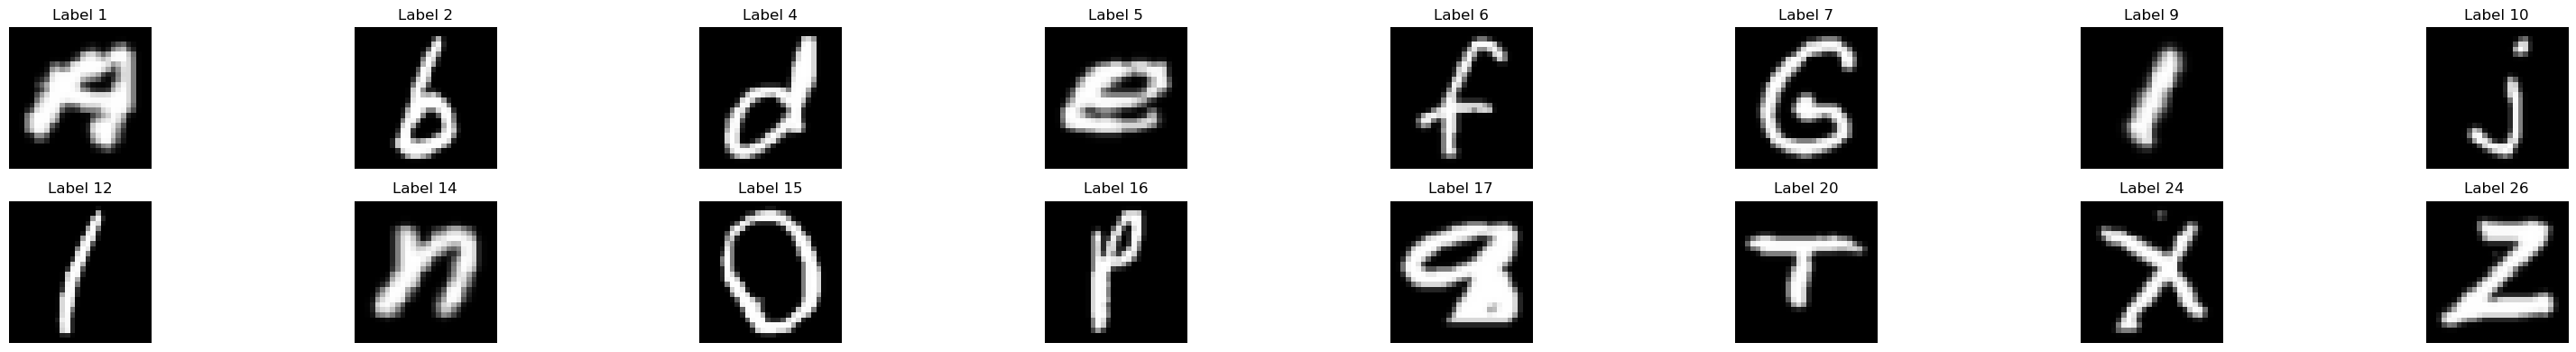

In [38]:
available_labels = sorted(np.unique(labels))

plt.figure(figsize=(len(available_labels) * 2, 4))  # Dynamic width based on number of labels

for i, label in enumerate(available_labels):
    # Find the first image index with this label
    idx = np.where(labels == label)[0][0]
    img = X_filtered[idx].reshape(28, 28)
    
    plt.subplot(2, (len(available_labels) + 1) // 2, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 3.5 **Creating TensorFlow Dataset**

In [64]:
BUFFER_SIZE = 10000
BATCH_SIZE = 128

# Create both labeled and unlabeled datasets for reuse
train_dataset = tf.data.Dataset.from_tensor_slices(X_filtered) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

labeled_train_dataset = tf.data.Dataset.from_tensor_slices((X_filtered, y_filtered)) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

## **Part 4: Model Performance Metrics**
---

### 4.1 **Fréchet Inception Distance (FID)**

Metric used to evaluate the quality of images by comparing them to real images using a pre-trained neural network. 

In [ ]:
# Load Inception model once globally
inception_model = InceptionV3(include_top=False, pooling='avg', input_shape=(299, 299, 3))

def resize_and_rgb(images, size=299):
    resized = []
    for img in images:
        # Convert Tensor to NumPy if needed
        if isinstance(img, tf.Tensor):
            img = img.numpy()
        img_arr = np.squeeze(img)  # Now it's always a NumPy array
        img_pil = Image.fromarray((img_arr * 255).astype(np.uint8))
        img_resized = img_pil.resize((size, size), Image.BILINEAR)
        img_rgb = img_resized.convert('RGB')
        resized.append(np.array(img_rgb))
    return np.array(resized)
def preprocess_images_for_inception(images):
    # images expected shape: (N,H,W,3) scaled 0-1 float32
    return preprocess_input(images * 255.0)

def get_activations(images, model=inception_model, batch_size=10):
    activations = []
    n_batches = int(np.ceil(len(images) / batch_size))
    for i in range(n_batches):
        batch = images[i * batch_size:(i + 1) * batch_size]
        batch_pp = preprocess_images_for_inception(batch)
        act = model(batch_pp)
        activations.append(act.numpy())
    return np.vstack(activations)

def calculate_fid(real_images, generated_images):
    act1 = get_activations(real_images)
    act2 = get_activations(generated_images)

    mu1, sigma1 = act1.mean(axis=0), np.cov(act1, rowvar=False)
    mu2, sigma2 = act2.mean(axis=0), np.cov(act2, rowvar=False)

    ssdiff = np.sum((mu1 - mu2)**2)
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = ssdiff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return fid

In [41]:
def compute_intra_class_fid(real_images, real_labels, fake_images, fake_labels, resize_and_rgb, calculate_fid):
    unique_labels = np.unique(real_labels)
    fid_scores = []
    
    for label in unique_labels:
        # Select images of this class
        real_class_images = real_images[real_labels == label]
        fake_class_images = fake_images[fake_labels == label]

        # Skip if no fake images for this class
        if len(fake_class_images) == 0:
            continue
        
        # Prepare images for FID (resize, convert to RGB if needed)
        real_prepped = resize_and_rgb(real_class_images)
        fake_prepped = resize_and_rgb(fake_class_images)
        
        fid = calculate_fid(real_prepped, fake_prepped)
        fid_scores.append(fid)
    
    if len(fid_scores) == 0:
        return None
    
    # Return average intra-class FID
    return np.mean(fid_scores)

### 4.2 **Precison and Recall**

In [42]:
def calculate_precision_recall(discriminator, real_images, fake_images,
                               real_labels=None, fake_labels=None,
                               conditional=False, threshold=0.5, batch_size=256):
    real_probs = []
    fake_probs = []

    for i in range(0, real_images.shape[0], batch_size):
        real_batch = real_images[i:i+batch_size]
        fake_batch = fake_images[i:i+batch_size]

        if conditional:
            real_label_batch = real_labels[i:i+batch_size]
            fake_label_batch = fake_labels[i:i+batch_size]
            real_score = discriminator([real_batch, real_label_batch], training=False)
            fake_score = discriminator([fake_batch, fake_label_batch], training=False)
        else:
            real_score = discriminator(real_batch, training=False)
            fake_score = discriminator(fake_batch, training=False)

        real_probs.append(real_score)
        fake_probs.append(fake_score)

    real_scores = tf.concat(real_probs, axis=0)
    fake_scores = tf.concat(fake_probs, axis=0)

    all_scores = tf.concat([real_scores, fake_scores], axis=0)
    min_score = tf.reduce_min(all_scores)
    max_score = tf.reduce_max(all_scores)

    tf.print("min_score:", min_score)
    tf.print("max_score:", max_score)

    score_range = max_score - min_score
    tf.print("score_range:", score_range)

    if score_range < 1e-8:
        tf.print("Score range too small — skipping precision/recall calculation")
        return None, None  # Change here so it fails loudly instead of silently

    norm_real = (real_scores - min_score) / (score_range + 1e-8)
    norm_fake = (fake_scores - min_score) / (score_range + 1e-8)

    real_preds = tf.cast(norm_real > threshold, tf.int32)
    fake_preds = tf.cast(norm_fake > threshold, tf.int32)

    TP = tf.reduce_sum(tf.cast(fake_preds == 0, tf.float32))
    FP = tf.reduce_sum(tf.cast(real_preds == 0, tf.float32))
    FN = tf.reduce_sum(tf.cast(fake_preds == 1, tf.float32))

    tf.print("TP:", TP)
    tf.print("FP:", FP)
    tf.print("FN:", FN)

    precision_den = TP + FP
    recall_den = TP + FN

    tf.print("Precision Denominator:", precision_den)
    tf.print("Recall Denominator:", recall_den)

    precision = TP / (precision_den + 1e-8) if precision_den > 0 else tf.constant(0.0)
    recall = TP / (recall_den + 1e-8) if recall_den > 0 else tf.constant(0.0)

    tf.print("Precision:", precision)
    tf.print("Recall:", recall)

    return precision.numpy().item(), recall.numpy().item()



### 4.3 **Visual Evaluation** 

In [43]:
def show_generated_images(generator, noise_dim, epoch, conditional=False, num_classes=None):
    noise = tf.random.normal([25, noise_dim])

    if conditional:
        if num_classes is None:
            raise ValueError("You must specify `num_classes` when using conditional=True.")
        # Create random one-hot encoded labels
        random_labels = tf.random.uniform([25], minval=0, maxval=num_classes, dtype=tf.int32)
        random_labels_one_hot = tf.one_hot(random_labels, depth=num_classes)
        fake_images = generator([noise, random_labels_one_hot], training=False)
    else:
        fake_images = generator(noise, training=False)

    # Scale images from [-1, 1] to [0, 1]
    fake_images_scaled = (fake_images + 1) / 2.0

    plt.figure(figsize=(5, 5))
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(fake_images_scaled[i, :, :, 0], cmap='gray')
        plt.axis('off')
    plt.suptitle(f'Generated Images (Epoch {epoch})')
    plt.tight_layout()
    plt.show()

### 4.4 **t-SNE Evaluation**

In [45]:
def plot_tsne_evaluation(generator, real_images, noise_dim,
                         conditional=False, num_classes=None, num_samples=49):
    print("=== Running t-SNE Evaluation ===")

    # Generate noise
    tsne_noise = tf.random.normal([num_samples, noise_dim])

    if conditional:
        if num_classes is None:
            raise ValueError("`num_classes` must be provided for conditional GAN.")
        tsne_labels = tf.random.uniform([num_samples], minval=0, maxval=num_classes, dtype=tf.int32)
        tsne_labels_one_hot = tf.one_hot(tsne_labels, depth=num_classes)
        tsne_fake_images = generator([tsne_noise, tsne_labels_one_hot], training=False)
    else:
        tsne_fake_images = generator(tsne_noise, training=False)

    # Rescale from [-1, 1] to [0, 1]
    tsne_fake_images = (tsne_fake_images + 1) / 2.0
    tsne_real_images = real_images[:num_samples]

    # Flatten images for t-SNE
    tsne_input = tf.concat([
        tf.reshape(tsne_fake_images, [num_samples, -1]),
        tf.reshape(tsne_real_images, [num_samples, -1])
    ], axis=0)

    # Perform t-SNE
    tsne = TSNE(n_components=2, perplexity=30, n_iter=300, init='pca', random_state=42)
    tsne_result = tsne.fit_transform(tsne_input.numpy())

    # Plot
    plt.figure(figsize=(6, 6))
    plt.scatter(tsne_result[:num_samples, 0], tsne_result[:num_samples, 1],
                label='Fake', alpha=0.6, marker='o')
    plt.scatter(tsne_result[num_samples:, 0], tsne_result[num_samples:, 1],
                label='Real', alpha=0.6, marker='^')
    plt.title("t-SNE Visualization of Real vs Generated Images")
    plt.legend()
    plt.tight_layout()
    plt.show()

### 4.5 **Storing Metrics**

In [44]:
def save_metrics_to_file(filename, epoch, gen_loss, disc_loss, precision, recall, fid_score=None, intra_fid_score=None, model_type="model"):
    os.makedirs("checkpoints", exist_ok=True)
    full_filename = f"checkpoints/{model_type}_epoch{epoch+1}_{filename}"
    with open(full_filename, "a") as f:
        f.write(f"Epoch {epoch + 1}:\n")
        f.write(f"Generator Loss: {gen_loss:.4f}\n")
        f.write(f"Discriminator Loss: {disc_loss:.4f}\n")
        # Handle None values for precision and recall
        precision = precision if precision is not None else 0.0
        recall = recall if recall is not None else 0.0
        f.write(f"Precision: {precision:.4f}, Recall: {recall:.4f}\n")
        if fid_score is not None:
            f.write(f"FID: {fid_score:.4f}\n")
        if intra_fid_score is not None:
            f.write(f"Intra-class FID: {intra_fid_score:.4f}\n")
        f.write("--------\n")

def save_generated_images(generator, epoch, noise_dim=100, num_images=49, model_type="model",
                          conditional=False, num_classes=None):
    os.makedirs("generated_images", exist_ok=True)
    filename = f"generated_images/{model_type}_epoch_{epoch + 1}.png"
    
    noise = tf.random.normal([num_images, noise_dim])
    
    if conditional:
        # Generate one-hot encoded random labels
        random_labels = tf.random.uniform([num_images], minval=0, maxval=num_classes, dtype=tf.int32)
        random_labels_one_hot = tf.one_hot(random_labels, depth=num_classes)
        generated_images = generator([noise, random_labels_one_hot], training=False)
    else:
        generated_images = generator(noise, training=False)

    # Rescale images to [0, 1] from [-1, 1]
    generated_images = (generated_images + 1.0) / 2.0

    # Plotting
    plt.figure(figsize=(7, 7))
    for i in range(num_images):
        plt.subplot(7, 7, i + 1)
        plt.imshow(generated_images[i, :, :, 0], cmap='gray')
        plt.axis('off')

    plt.tight_layout()
    plt.savefig(filename)
    plt.close()

### 4.6 **Metrics Against Epochs Graph**

In [46]:
def plot_metrics_over_epochs(precision_history, recall_history, gen_loss_history, disc_loss_history, model_type="model"):

    epochs = list(range(1, len(precision_history) + 1))
    
    plt.figure(figsize=(14, 6))

    # Precision and Recall subplot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, precision_history, label='Precision', color='blue', marker='o')
    plt.plot(epochs, recall_history, label='Recall', color='green', marker='x')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.title(f'{model_type} - Precision & Recall Over Epochs')
    plt.legend()
    plt.grid(True)

    # Generator and Discriminator Loss subplot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, gen_loss_history, label='Generator Loss', color='red', marker='o')
    plt.plot(epochs, disc_loss_history, label='Discriminator Loss', color='purple', marker='x')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{model_type} - Generator & Discriminator Loss Over Epochs')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

## **Part 5: Model Training & Evaluation**
---

### 5.1 **Utility Functions** 

#### 5.1.1 **Training Function**

In [47]:
def train(dataset, epochs, real_images, class_labels=None, model_type="model", conditional=False):

    precision_history = []
    recall_history = []
    gen_loss_history = []
    disc_loss_history = []

    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")
        epoch_gen_loss = []
        epoch_disc_loss = []

        for batch in dataset:
            if conditional:
                # Expect dataset yields (images, labels)
                image_batch, label_batch = batch
                gen_loss, disc_loss = train_step(image_batch, label_batch)
            else:
                # Expect dataset yields just images
                image_batch = batch
                gen_loss, disc_loss = train_step(image_batch)

            epoch_gen_loss.append(gen_loss.numpy())
            epoch_disc_loss.append(disc_loss.numpy())

        avg_gen_loss = np.mean(epoch_gen_loss)
        avg_disc_loss = np.mean(epoch_disc_loss)
        gen_loss_history.append(avg_gen_loss)
        disc_loss_history.append(avg_disc_loss)

        print(f"Generator Loss: {avg_gen_loss:.4f}, Discriminator Loss: {avg_disc_loss:.4f}")

        # === Run evaluation at the end of the epoch ===
        metrics = evaluate_gan(generator, discriminator, noise_dim, real_images,
                            seed_noise=eval_seed,
                            precision_history=precision_history,
                            recall_history=recall_history,
                            class_labels=class_labels,
                            conditional=conditional)

        # Print results
        print(f"Avg Discriminator Confidence: {metrics['avg_disc_score']:.4f}")
        print(f"Real Images - Mean: {metrics['real_mean']:.4f}, Std: {metrics['real_std']:.4f}")
        print(f"Fake Images - Mean: {metrics['fake_mean']:.4f}, Std: {metrics['fake_std']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}, Recall: {metrics['recall']:.4f}")
        if metrics['fid_score'] is not None:
            print(f"FID Score: {metrics['fid_score']:.4f}")
        if metrics['intra_fid_score'] is not None:
            print(f"Intra-class FID Score: {metrics['intra_fid_score']:.4f}")

        # Optionally show generated images during training
        show_generated_images(generator, noise_dim, epoch + 1)

        # === Only save & plot on last epoch ===
        if epoch == epochs - 1:

            os.makedirs("checkpoints", exist_ok=True)
            generator.save_weights(f"checkpoints/generator_{model_type}__epoch_{epoch + 1}.h5")
            discriminator.save_weights(f"checkpoints/discriminator_{model_type}_epoch_{epoch + 1}.h5")

            save_metrics_to_file(
                epoch,
                avg_gen_loss,
                avg_disc_loss,
                metrics['precision'],
                metrics['recall'],
                metrics['fid_score'],
                metrics['intra_fid_score'],
                model_type=model_type
            )

            save_generated_images(generator, epoch, noise_dim=256, num_images=49, model_type=model_type, 
                                  conditional=conditional, num_classes=16)

            plot_metrics_over_epochs(
                precision_history,
                recall_history,
                gen_loss_history,
                disc_loss_history,
                model_type=model_type
            )

            plot_tsne_evaluation(generator, real_images, noise_dim)

#### 5.1.2 **Evaluation Function**

In [48]:
def evaluate_gan(generator, discriminator, noise_dim, real_images,
                 class_labels=None, generated_labels=None, seed_noise=None,
                 epoch=None, total_epochs=None,
                 precision_history=None, recall_history=None,
                 gen_loss_history=None, disc_loss_history=None,
                 conditional=False):
    
    # Generate noise
    if seed_noise is not None:
        noise = seed_noise
        num_samples = noise.shape[0]
    else:
        noise = tf.random.normal([100, noise_dim])
        num_samples = 100
    
    if conditional:
        if generated_labels is None:
            labels = tf.random.uniform([num_samples, 1], minval=0, maxval=16, dtype=tf.int32)
        else:
            labels = generated_labels

        fake_images = generator([noise, labels], training=False)
        disc_scores = discriminator([fake_images, labels], training=False)
    else:
        fake_images = generator(noise, training=False)
        disc_scores = discriminator(fake_images, training=False)

    fake_images_scaled = (fake_images + 1) / 2.0
    num_fake = fake_images.shape[0]

    avg_disc_score = tf.reduce_mean(disc_scores).numpy()

    real_images_scaled = (real_images[:num_fake] + 1) / 2.0
    pixel_diff = tf.reduce_mean(tf.abs(fake_images_scaled - real_images_scaled)).numpy()

    real_scaled = (real_images + 1) / 2.0 if real_images.min() < 0 else real_images / 255.0
    fake_scaled = fake_images_scaled.numpy()
    fake_mean, fake_std = fake_scaled.mean(), fake_scaled.std()
    real_mean, real_std = real_scaled.mean(), real_scaled.std()

    # Calculate FID and intra-class FID only at the last epoch
    if epoch is not None and total_epochs is not None and epoch == total_epochs - 1:
        print("Calculating FID and intra-class FID...")
        real_for_fid = resize_and_rgb(real_scaled)
        fake_for_fid = resize_and_rgb(fake_scaled)
        fid_score = calculate_fid(real_for_fid, fake_for_fid)

        if (class_labels is not None and generated_labels is not None
                and len(np.unique(generated_labels)) > 1):
            intra_fid_score = compute_intra_class_fid(
                real_scaled, class_labels, fake_scaled, generated_labels,
                resize_and_rgb, calculate_fid
            )
        else:
            intra_fid_score = None
    else:
        fid_score = None
        intra_fid_score = None

    if class_labels is not None:
        class_labels = tf.cast(class_labels, tf.int32)
        if len(class_labels.shape) == 1:
            class_labels = tf.expand_dims(class_labels, axis=-1)

    if generated_labels is None and class_labels is not None:
        generated_labels = tf.random.uniform(
            [fake_images.shape[0], 1], minval=0, maxval=16, dtype=tf.int32)
    
    precision, recall = calculate_precision_recall(discriminator, real_images, fake_images, real_labels=class_labels, fake_labels=generated_labels, conditional=conditional)

    if precision_history is not None:
        precision_history.append(precision)
    if recall_history is not None:
        recall_history.append(recall)

    return {
        "avg_disc_score": avg_disc_score,
        "real_mean": real_mean,
        "real_std": real_std,
        "fake_mean": fake_mean,
        "fake_std": fake_std,
        "pixel_diff": pixel_diff,
        "fid_score": fid_score,
        "intra_fid_score": intra_fid_score,
        "precision": precision,
        "recall": recall,
        "fake_images": fake_images,
    }



## **Part 6: Model Building & Training**
---

### 6.1 **Baseline Models**

#### 6.1.1 **DCGAN**

In [49]:
# === 2. Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)), 
        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === 3. Discriminator Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

# === 4. Loss & Optimizer ===
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator = make_generator_model()
discriminator = make_discriminator_model()

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)


Epoch 1/2
Generator Loss: 2.7763, Discriminator Loss: 0.4900
min_score: -9.1848278
max_score: 6.38321972
score_range: 15.5680475
TP: 785
FP: 2456
FN: 215
Precision Denominator: 3241
Recall Denominator: 1000
Precision: 0.242209196
Recall: 0.785
Avg Discriminator Confidence: -3.5085
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.4097, Std: 0.4357
Precision: 0.2422, Recall: 0.7850


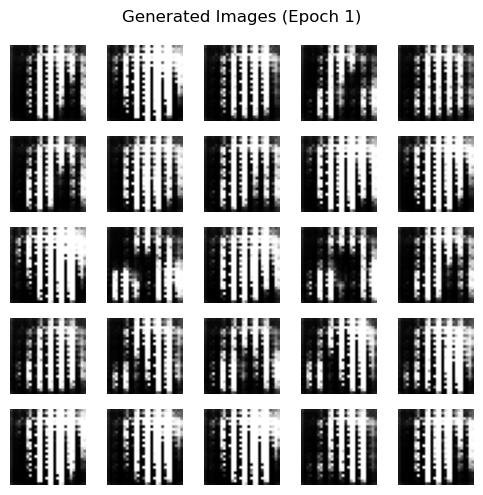


Epoch 2/2
Generator Loss: 1.7777, Discriminator Loss: 0.9146
min_score: -7.53159571
max_score: 6.9977994
score_range: 14.5293951
TP: 314
FP: 14215
FN: 686
Precision Denominator: 14529
Recall Denominator: 1000
Precision: 0.0216119494
Recall: 0.314
Avg Discriminator Confidence: 0.3401
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1818, Std: 0.3078
Precision: 0.0216, Recall: 0.3140


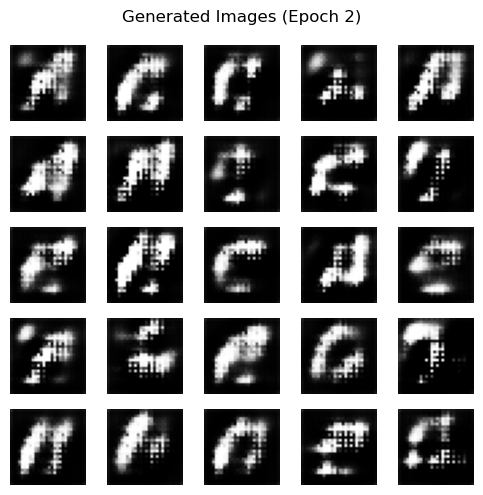

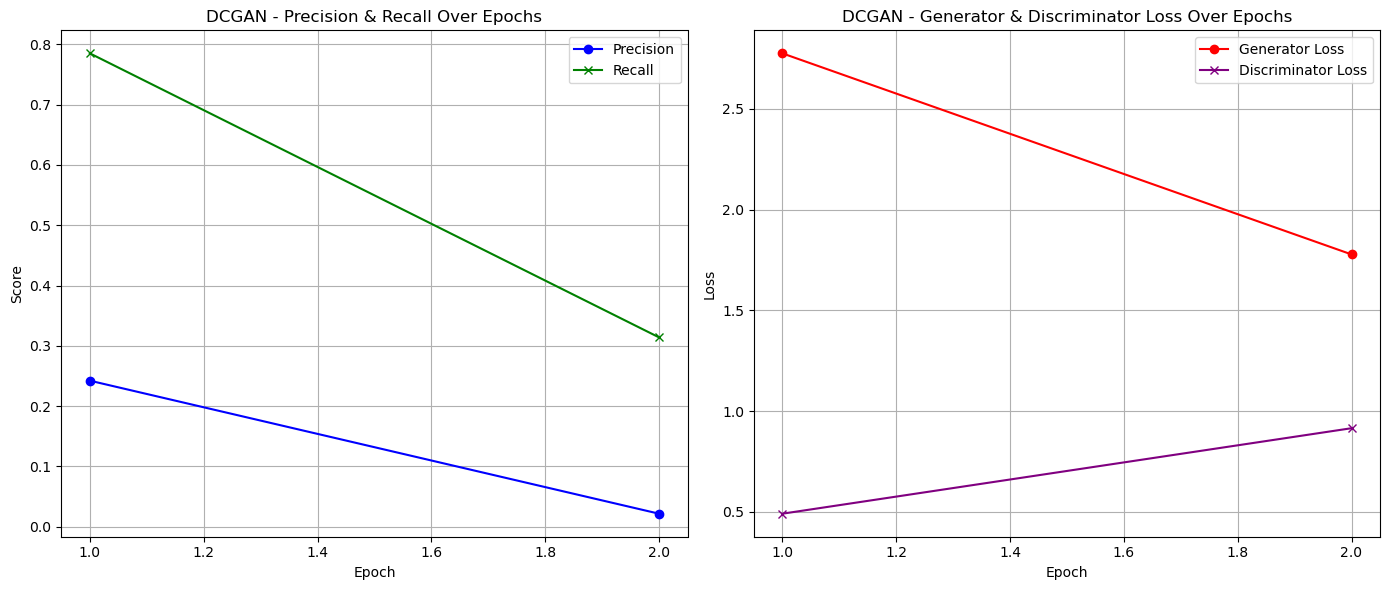

=== Running t-SNE Evaluation ===


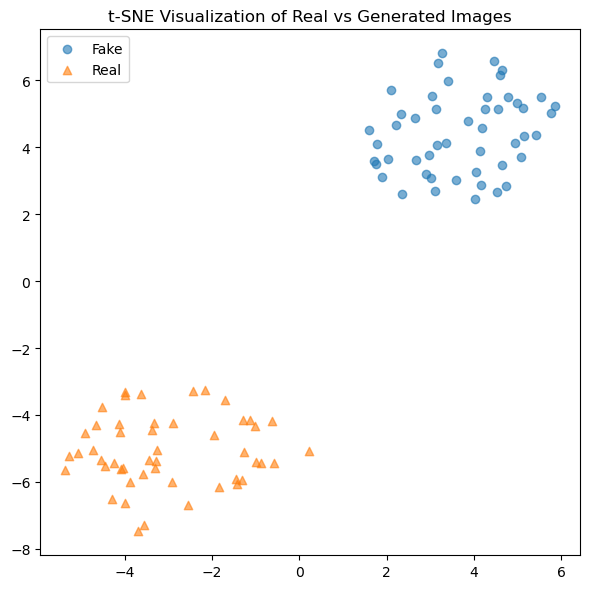

In [50]:
# === 5. Training Loop ===
EPOCHS = 2
noise_dim = 256
model_type = "DCGAN"

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

eval_seed = tf.random.normal([1000, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

# Start training
train(train_dataset, EPOCHS, real_images=X_filtered, model_type=model_type, conditional=False)

#### 6.1.2 **WGAN-GP**

In [51]:
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)),

        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

In [52]:
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)  # No activation for WGAN
    ])
    return model

In [53]:
# === Gradient Penalty ===
def gradient_penalty(discriminator, real_images, fake_images):
    batch_size = real_images.shape[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
    interpolated = real_images + alpha * (fake_images - real_images)
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        pred = discriminator(interpolated, training=True)
    grads = tape.gradient(pred, [interpolated])[0]
    grads = tf.reshape(grads, [batch_size, -1])
    grads_norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-12)
    gp = tf.reduce_mean((grads_norm - 1.0) ** 2)
    return gp

In [54]:
# === Loss functions ===
def discriminator_loss(real_output, fake_output, gp, lambda_gp=10.0):
    return tf.reduce_mean(fake_output) - tf.reduce_mean(real_output) + lambda_gp * gp

def generator_loss(fake_output):
    return -tf.reduce_mean(fake_output)

In [55]:
# === Optimizers ===
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)

# === Create models ===
generator = make_generator_model()
discriminator = make_discriminator_model()


Epoch 1/5
Generator Loss: -6.8293, Discriminator Loss: -7.0595
min_score: 5.84851551
max_score: 13.4837399
score_range: 7.63522434
TP: 782
FP: 32857
FN: 218
Precision Denominator: 33639
Recall Denominator: 1000
Precision: 0.0232468266
Recall: 0.782
Avg Discriminator Confidence: 8.9229
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1655, Std: 0.3192
Precision: 0.0232, Recall: 0.7820


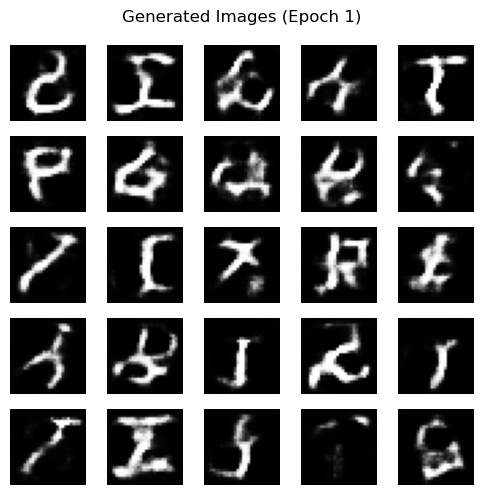


Epoch 2/5
Generator Loss: -6.1471, Discriminator Loss: -0.7912
min_score: -4.13734388
max_score: 10.5589876
score_range: 14.696331
TP: 927
FP: 45577
FN: 73
Precision Denominator: 46504
Recall Denominator: 1000
Precision: 0.0199337695
Recall: 0.927
Avg Discriminator Confidence: 0.9812
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1662, Std: 0.3243
Precision: 0.0199, Recall: 0.9270


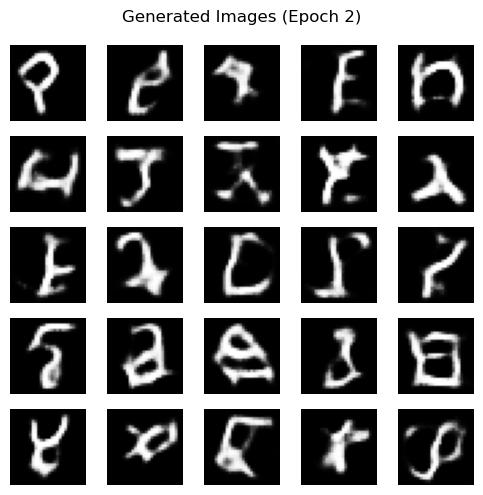


Epoch 3/5
Generator Loss: -4.6007, Discriminator Loss: -0.7263
min_score: 1.47163439
max_score: 13.8949547
score_range: 12.4233208
TP: 390
FP: 17528
FN: 610
Precision Denominator: 17918
Recall Denominator: 1000
Precision: 0.0217658225
Recall: 0.39
Avg Discriminator Confidence: 8.1774
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1708, Std: 0.3259
Precision: 0.0218, Recall: 0.3900


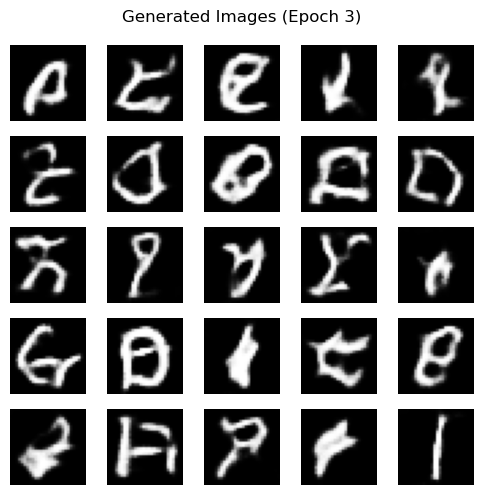


Epoch 4/5
Generator Loss: -4.3993, Discriminator Loss: -0.7248
min_score: 0.266305923
max_score: 9.7231369
score_range: 9.45683098
TP: 544
FP: 20530
FN: 456
Precision Denominator: 21074
Recall Denominator: 1000
Precision: 0.0258138
Recall: 0.544
Avg Discriminator Confidence: 4.8207
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1627, Std: 0.3190
Precision: 0.0258, Recall: 0.5440


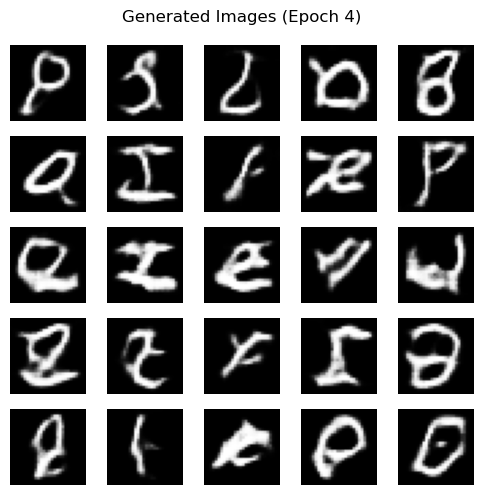


Epoch 5/5
Generator Loss: -4.3871, Discriminator Loss: -0.7264
min_score: -4.163661
max_score: 8.86770725
score_range: 13.0313683
TP: 673
FP: 32376
FN: 327
Precision Denominator: 33049
Recall Denominator: 1000
Precision: 0.0203637015
Recall: 0.673
Avg Discriminator Confidence: 1.3621
Real Images - Mean: 0.1723, Std: 0.3313
Fake Images - Mean: 0.1677, Std: 0.3247
Precision: 0.0204, Recall: 0.6730


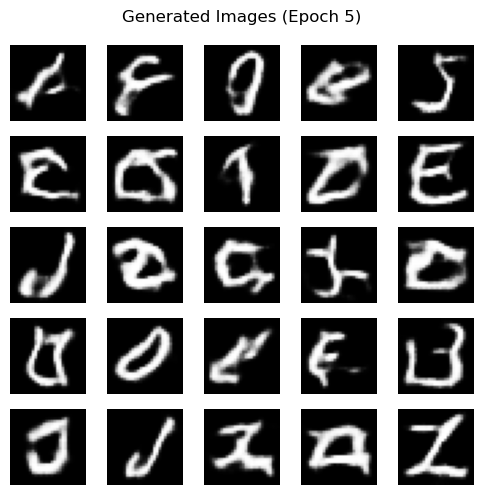

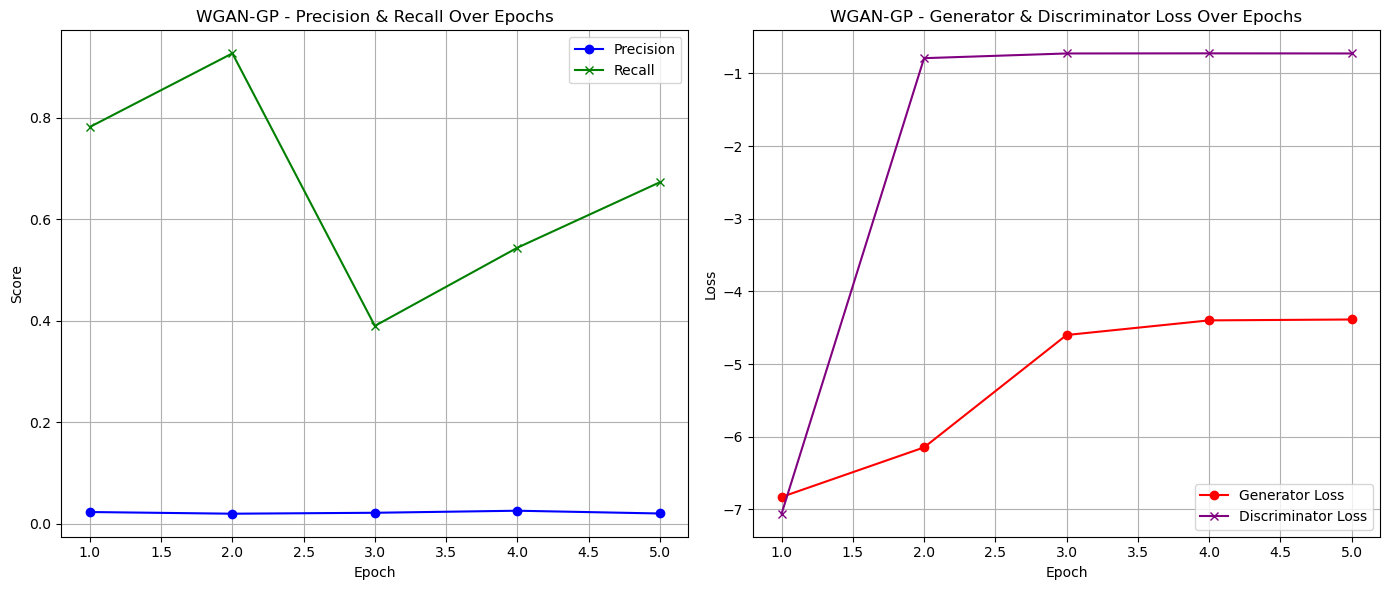

=== Running t-SNE Evaluation ===


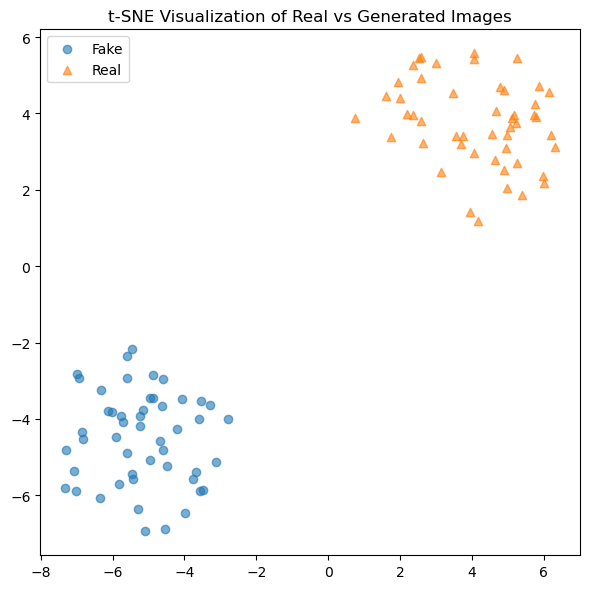

In [56]:
# === Hyperparameters ===
EPOCHS = 5
noise_dim = 256
BATCH_SIZE = 64
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10.0
model_type = "WGAN-GP"

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    # Update discriminator (critic) multiple times
    for _ in range(CRITIC_ITERATIONS):
        noise = tf.random.normal([batch_size, noise_dim])
        with tf.GradientTape() as disc_tape:
            fake_images = generator(noise, training=True)
            real_output = discriminator(real_images, training=True)
            fake_output = discriminator(fake_images, training=True)
            gp = gradient_penalty(discriminator, real_images, fake_images)
            disc_loss = discriminator_loss(real_output, fake_output, gp, LAMBDA_GP)
        gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    # Update generator once
    noise = tf.random.normal([batch_size, noise_dim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))

    return gen_loss, disc_loss

# Start training
train(train_dataset, EPOCHS, real_images=X_filtered, model_type=model_type, conditional=False)

#### 6.1.3 **cGAN**

In [72]:
# === Loss & Optimizers ===
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

In [73]:
# === Generator ===
def make_generator_model():
    noise_input = layers.Input(shape=(256,))
    label_input = layers.Input(shape=(1,), dtype='int32')
    label_embedding = layers.Embedding(16, 256)(label_input)
    label_embedding = layers.Flatten()(label_embedding)
    x = layers.Multiply()([noise_input, label_embedding])
    x = layers.Dense(7*7*256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Reshape((7, 7, 256))(x)
    x = layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding='same', use_bias=False, activation='tanh')(x)
    return tf.keras.Model([noise_input, label_input], x, name="cGAN_Generator")

# === Discriminator ===
def make_discriminator_model():
    image_input = layers.Input(shape=(28,28,1))
    label_input = layers.Input(shape=(1,), dtype='int32')
    label_embedding = layers.Embedding(16, 28*28)(label_input)
    label_embedding = layers.Reshape((28,28,1))(label_embedding)
    x = layers.Concatenate(axis=-1)([image_input, label_embedding])
    x = layers.Conv2D(64, (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv2D(128, (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(1)(x)
    return tf.keras.Model([image_input, label_input], x, name="cGAN_Discriminator")

In [74]:
generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

# === Build models ===
generator = make_generator_model()
discriminator = make_discriminator_model()

In [ ]:
# === Constants ===
EPOCHS = 3
BATCH_SIZE = 128
model_type = "cGAN"

@tf.function
def train_step(images, labels=None):
    batch_size = tf.shape(images)[0]
    noise = tf.random.normal([batch_size, 256])
    
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        if labels is not None:
            # Conditional GAN
            generated_images = generator([noise, labels], training=True)
            real_output = discriminator([images, labels], training=True)
            fake_output = discriminator([generated_images, labels], training=True)
        else:
            # Unconditional GAN
            generated_images = generator(noise, training=True)
            real_output = discriminator(images, training=True)
            fake_output = discriminator(generated_images, training=True)
        
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)
    d
    # Calculate gradients
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    
    # Apply gradients
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))
    
    return gen_loss, disc_loss

# === Train ===
train(labeled_train_dataset, EPOCHS, real_images=X_filtered, class_labels=y_filtered, model_type=model_type, conditional=True)


Epoch 1/3
Generator Loss: 0.7281, Discriminator Loss: 1.2251


InvalidArgumentError: Exception encountered when calling layer "multiply_2" "                 f"(type Multiply).

{{function_node __wrapped__Mul_device_/job:localhost/replica:0/task:0/device:GPU:0}} required broadcastable shapes [Op:Mul]

Call arguments received by layer "multiply_2" "                 f"(type Multiply):
  • inputs=['tf.Tensor(shape=(1000, 256), dtype=float32)', 'tf.Tensor(shape=(100, 256), dtype=float32)']

#### 6.1.4 **ACGAN**

In [ ]:
NOISE_DIM = 100

# Generator same conditioning as cGAN (noise + label)
def make_generator_model():
    noise_input = layers.Input(shape=(NOISE_DIM,))
    label_input = layers.Input(shape=(1,), dtype='int32')

    label_embedding = layers.Embedding(16, NOISE_DIM)(label_input)
    label_embedding = layers.Flatten()(label_embedding)

    x = layers.Multiply()([noise_input, label_embedding])

    x = layers.Dense(7*7*256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Reshape((7,7,256))(x)

    x = layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding='same', use_bias=False, activation='tanh')(x)

    return tf.keras.Model([noise_input, label_input], x, name="ACGAN_Generator")

# Discriminator outputs real/fake score + class prediction
def make_discriminator_model():
    image_input = layers.Input(shape=(28,28,1))

    x = layers.Conv2D(64, (5,5), strides=(2,2), padding='same')(image_input)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, (5,5), strides=(2,2), padding='same')(x)
    x = layers.LeakyReLU()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)

    real_fake = layers.Dense(1)(x)  # Real/fake output (no activation if WGAN)
    class_output = layers.Dense(16, activation='softmax')(x)  # Class prediction output

    return tf.keras.Model(image_input, [real_fake, class_output], name="ACGAN_Discriminator")

# Example: Forward pass
generator = make_generator_model()
discriminator = make_discriminator_model()

noise = tf.random.normal([4, NOISE_DIM])
labels = tf.constant([0,1,2,3], dtype=tf.int32)

fake_images = generator([noise, labels])
real_fake_logits, class_logits = discriminator(fake_images)

print(fake_images.shape, real_fake_logits.shape, class_logits.shape)

(4, 28, 28, 1) (4, 1) (4, 16)
